# UAV-LiDAR stem-volume phenotyping in radiata pine — single-site ssGBLUP heritability (adapted R demonstration)

**Paper:** Elleouet J.S., Jayathunga S., Graham N.J., Paget M.F., Klápště J., Hartley R.J.L. (2026).
*Using UAV-LiDAR for stem volume phenotyping in the genetic selection of radiata pine (Pinus radiata D. Don).*
Annals of Forest Science **83**:60, DOI [10.1186/s13595-026-01379-x](https://doi.org/10.1186/s13595-026-01379-x) (open access, CC BY 4.0).

**Author code:** [`JoaneElleouet/UAV-LiDAR_for_stem_volume_phenotyping_Prad`](https://github.com/JoaneElleouet/UAV-LiDAR_for_stem_volume_phenotyping_Prad) @ commit `ec9ed8f5055abf9f2aecda4fad18781df7a24469`
(the repository holds the R scripts for the paper's genetic analyses and an anonymised subset of the analytical data; it has no README or LICENSE file — reuse terms are unverified).

**Execution status (written before this run):** to be validated end-to-end in Colab; see the executed outputs.

**ADAPTED DEMONSTRATION — AI-assisted adaptation.** 🇯🇵 **適応版デモンストレーション（AI支援による移植）**
The authors ran ASReml-R 4.2.0.355 (commercial licence). ASReml-R cannot be licensed inside this notebook, so the REML engine is replaced with the open-source **sommer** package; the A/G/H relationship-matrix construction uses the authors' exact calls and packages (AGHmatrix, ASRgenomics) and the authors' malformation filter, and the same narrow-sense heritability formula. The authors did not provide this Colab implementation; the executed example and checks below were validated, but untested behaviour is not guaranteed.
/ 著者は商用のASReml-Rを使用しました。ライセンスの都合上、REML計算をオープンソースの **sommer** に置き換えています（行列構築は著者の関数・パッケージをそのまま使用）。このColab実装は著者提供ではないため、検証済みの範囲のみ結果を信用してください。

**What this notebook does (single minimal example):**
1. Downloads the authors' anonymised dataset (3 RDS files) from the pinned commit, inside Colab.
2. Recomputes allometric stem volume (ASV) with the paper's Eq. 1 (Kimberley & Beets 2007) and compares it with the authors' shared `vol.m3` column.
3. Reproduces the authors' **single-site ssGBLUP** pipeline for **trial 1 / trait `zmax.m`** (LiDAR tree height): pedigree A + genomic G blended into H (λ = 0.5), block + additive + non-additive + residual REML, and estimates narrow-sense heritability h² = V_A / (V_A + V_non-add + V_res).

**Out of scope:** the multi-site models, the bivariate DBH–zmax model, EBV/selection-utility analyses, the PBLUP comparison, the remaining 10 trials (the released data contain 2 anonymised trials), and LiDAR point-cloud processing.

**Runtime selection — CPU only.** 🇨🇵 **ランタイム: CPUのみで実行できます（GPU不要）**
The paper's genetic evaluation is REML linear algebra on small matrices (≤ ~2,400 pedigree individuals here); the authors used ordinary R on CPU. No GPU is used. Select **Runtime → Change runtime type → CPU** (the default is fine). Expected duration: a few minutes (package install ≈ 1–2 min, 32.5 MB download, model fit ≈ 1 min). Run all cells top to bottom ("Runtime → Run all").

**Check the R environment.** The analysis runs as R scripts (the authors' language) driven from Python with `Rscript`; this cell confirms that R is present on the Colab runtime and reports CPUs/RAM. 🇯🇵 R解析は著者と同じR言語で行います。このセルはColabランタイムにRがあるか（Rscriptのバージョン・CPU・メモリ）を確認します。

In [ ]:
import subprocess, pathlib, shlex

r = subprocess.run(['Rscript', '--version'], capture_output=True, text=True, timeout=60)
print('Rscript:', (r.stderr or r.stdout).strip())
print('CPUs:', __import__('os').cpu_count())
assert r.returncode == 0, 'Rscript is not available on this runtime'
pathlib.Path('data').mkdir(exist_ok=True)
print('work dir ready')

Rscript: Rscript (R) version 4.6.1 (2026-06-24)
CPUs: 2
work dir ready


**Install the R packages.** `dplyr/tidyr/tibble/ggplot2` (data handling and plots), `AGHmatrix` (VanRaden G, pedigree A — cited by the paper), `ASRgenomics` (G.inverse / H.inverse with blending λ — cited by the paper), and `sommer` (open-source REML engine replacing the commercial ASReml-R). Posit Package Manager serves prebuilt Linux binaries, so installation is fast. Observed versions in the validated run: AGHmatrix 3.0.3, ASRgenomics 1.1.6, sommer 4.5.27 on R 4.6.1. 🇯🇵 論文で引用されているパッケージ（AGHmatrix, ASRgenomics）とオープンソースのREMLエンジン sommer をインストールします（商用asremlはインストールしません）。

In [ ]:
import subprocess, pathlib

install_r = r'''
# Install R packages from Posit Package Manager (prebuilt Linux binaries)
options(warn = 1, timeout = 900)
codename <- trimws(system('. /etc/os-release; echo $VERSION_CODENAME', intern = TRUE))
cat('P3M codename:', codename, '\n')
repo <- sprintf('https://packagemanager.posit.co/cran/__linux__/%s/latest', codename)
options(repos = c(P3M = repo, CRAN = 'https://cloud.r-project.org'))
options(HTTPUserAgent = sprintf('R/%s R (%s)', getRversion(),
        paste(getRversion(), R.version$platform, R.version$arch, R.version$os)))
pkgs <- c('dplyr', 'tidyr', 'tibble', 'ggplot2', 'AGHmatrix', 'ASRgenomics', 'sommer')
install.packages(pkgs, Ncpus = 2)
for (p in pkgs) cat(p, as.character(packageVersion(p)), '\n')
'''
pathlib.Path('install_r.R').write_text(install_r)
r = subprocess.run(['Rscript', 'install_r.R'], capture_output=True, text=True, timeout=2400)
print(r.stdout)
if r.returncode:
    print(r.stderr[-2000:])
    raise RuntimeError(f'R package install failed (exit {r.returncode})')

P3M codename: noble 
begin installing package ‘fracdiff’
begin installing package ‘colorspace’
* installing *binary* package ‘fracdiff’ ...
* package ‘fracdiff’ successfully unpacked and SHA256 sums checked
* DONE (fracdiff)
begin installing package ‘timeDate’
* installing *binary* package ‘colorspace’ ...
* package ‘colorspace’ successfully unpacked and SHA256 sums checked
* DONE (colorspace)
begin installing package ‘urca’
* installing *binary* package ‘timeDate’ ...
* package ‘timeDate’ successfully unpacked and SHA256 sums checked
* DONE (timeDate)
begin installing package ‘zoo’
* installing *binary* package ‘urca’ ...
* package ‘urca’ successfully unpacked and SHA256 sums checked
* DONE (urca)
begin installing package ‘Deriv’
* installing *binary* package ‘zoo’ ...
* package ‘zoo’ successfully unpacked and SHA256 sums checked
* DONE (zoo)
begin installing package ‘rbibutils’
* installing *binary* package ‘Deriv’ ...
* package ‘Deriv’ successfully unpacked and SHA256 sums checked
*

**Download the authors' anonymised data (Colab-only).** Three binary RDS files from the pinned commit `ec9ed8f5055a` via raw.githubusercontent.com. Each download is verified against the GitHub tree metadata: exact byte size and git blob SHA-1, with a Git-LFS-pointer rejection. 🇯🇵 著者リポジトリの固定コミットから、本研究に必要な匿名化データ3ファイルのみColab内にダウンロードし、バイト数とgit blob SHA-1で完全性を検証します（LFSポインタは拒否）。

In [ ]:
import urllib.request, hashlib, pathlib

COMMIT = 'ec9ed8f5055abf9f2aecda4fad18781df7a24469'
BASE = 'https://raw.githubusercontent.com/JoaneElleouet/UAV-LiDAR_for_stem_volume_phenotyping_Prad/' + COMMIT + '/data/'
# size and git blob sha1 from the GitHub tree API for the pinned commit
EXPECTED = {
    'phenotypes_anonymised.rds': (129550,    '7579a79a06ac7adad76876c8152a873d65b80e67'),
    'pedigree_anonymised.rds':   (35444,     '0431954ca2e93b4cb588f9b645dbe1b456f5af36'),
    'Gmatrix_anonymised.rds':    (32287401,  '21946fb813320ccd3fe2cffc7f68428f42d1551a'),
}
for name, (size, blob_sha) in EXPECTED.items():
    req = urllib.request.Request(BASE + name, headers={'User-Agent': 'colab-demo/1.0'})
    blob = urllib.request.urlopen(req, timeout=300).read()
    assert len(blob) == size, f'{name}: expected {size} bytes, got {len(blob)}'
    assert not blob.startswith(b'version https://git-lfs'), f'{name}: Git LFS pointer, not payload'
    got = hashlib.sha1(b'blob ' + str(len(blob)).encode() + b'\x00' + blob).hexdigest()
    assert got == blob_sha, f'{name}: blob sha mismatch ({got})'
    pathlib.Path('data', name).write_bytes(blob)
    print(f'{name}: {len(blob)} bytes, git blob sha1 verified OK')

phenotypes_anonymised.rds: 129550 bytes, git blob sha1 verified OK
pedigree_anonymised.rds: 35444 bytes, git blob sha1 verified OK


Gmatrix_anonymised.rds: 32287401 bytes, git blob sha1 verified OK


**Inspect the data schema and preview the inputs.** 🇯🇵 ダウンロードしたRDSを読み込み、列名・試験区・形質の分布を確認します（スキーマは著者スクリプトから推定していましたが、ここで実データを検証）。The malformation codes in `tree_form_code` are exactly the codes the authors' filter removes (`ML|DL|FK|BW|BL|BT|DF|LL|LR|TO`). A preview scatter (DBH vs LiDAR height per trial) is saved as a PNG.

phenotypes dim: 3972 x 15 
columns: trial, GenotypeName, grid_id, tree_id, stem_number, tree_form_code, dbh.m, zmax.m, n, area, concavehull2D_area, convexhull2D_area, convexhull3D_area, convexhull3D_volume, vol.m3 
trials: trial_1, trial_2 
rows per trial:

trial_1 trial_2 
   1978    1994 

tree_form_code (malformation) codes, most frequent:

         CK CK RC    RC    DL CK DL    SS    LL    BW CK LL CK SS    ML 
 1164   497   420   391   331   262   205   156   136   107    86    69 

summary of model traits:
     dbh.m            zmax.m       convexhull3D_area     vol.m3       
 Min.   :0.0900   Min.   : 5.160   Min.   : 17.94    Min.   :0.01894  
 1st Qu.:0.1380   1st Qu.: 8.030   1st Qu.: 51.69    1st Qu.:0.05995  
 Median :0.1600   Median : 9.130   Median : 64.17    Median :0.08491  
 Mean   :0.1576   Mean   : 9.262   Mean   : 65.57    Mean   :0.08729  
 3rd Qu.:0.1780   3rd Qu.:10.500   3rd Qu.: 78.14    3rd Qu.:0.11166  
 Max.   :0.2410   Max.   :13.910   Max.   :154.58    Max

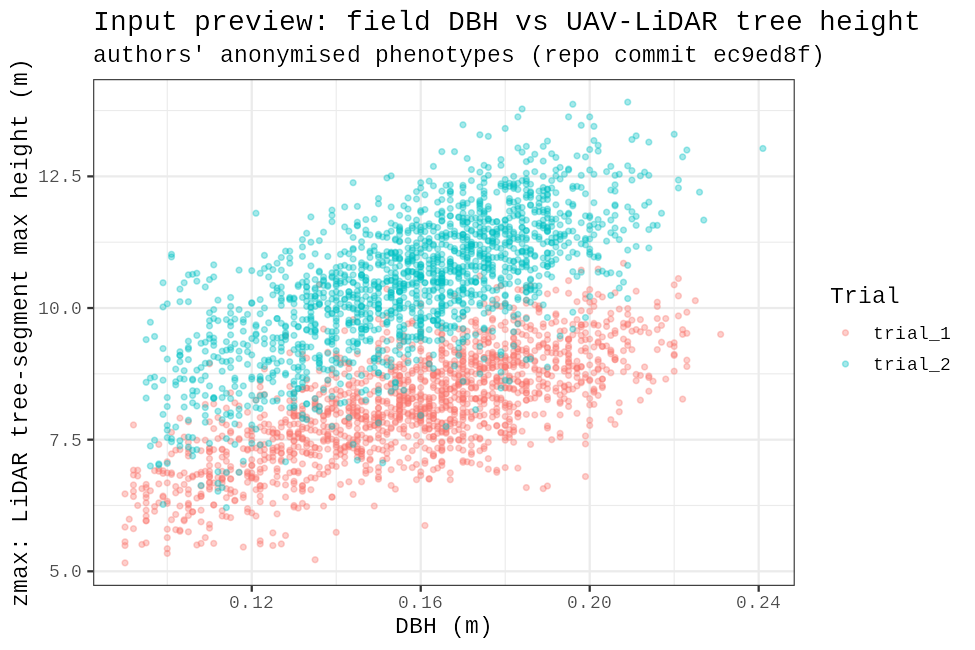

In [ ]:
import subprocess, pathlib

schema_r = r'''
# Schema inspection and input preview (authors' anonymised data, commit ec9ed8f)
suppressMessages({library(dplyr); library(ggplot2)})
dir.create('out', showWarnings = FALSE)
dat <- readRDS('data/phenotypes_anonymised.rds')
cat('phenotypes dim:', nrow(dat), 'x', ncol(dat), '\n')
cat('columns:', paste(names(dat), collapse = ', '), '\n')
cat('trials:', paste(sort(unique(as.character(dat$trial))), collapse = ', '), '\n')
cat('rows per trial:\n'); print(table(dat$trial))
cat('\ntree_form_code (malformation) codes, most frequent:\n')
print(head(sort(table(dat$tree_form_code, useNA = 'ifany'), decreasing = TRUE), 12))
cat('\nsummary of model traits:\n')
print(summary(dat[, c('dbh.m', 'zmax.m', 'convexhull3D_area', 'vol.m3')]))
cat('\nfirst 5 rows (key columns):\n')
print(head(dat[, c('trial', 'GenotypeName', 'grid_id', 'tree_form_code',
                   'dbh.m', 'zmax.m', 'vol.m3')], 5))

pv <- dat[!is.na(dat[['dbh.m']]) & !is.na(dat[['zmax.m']]), ]
p <- ggplot(pv, aes(x = .data[['dbh.m']], y = .data[['zmax.m']], colour = trial)) +
  geom_point(alpha = 0.35, size = 1.1) +
  labs(title = 'Input preview: field DBH vs UAV-LiDAR tree height',
       subtitle = "authors' anonymised phenotypes (repo commit ec9ed8f)",
       x = 'DBH (m)', y = 'zmax: LiDAR tree-segment max height (m)', colour = 'Trial') +
  theme_bw(13)
ggsave('out/preview_dbh_zmax.png', p, width = 7.5, height = 5, dpi = 130)
cat('saved out/preview_dbh_zmax.png\n')
'''
pathlib.Path('script_a_schema.R').write_text(schema_r)
r = subprocess.run(['Rscript', 'script_a_schema.R'], capture_output=True, text=True, timeout=1200)
print(r.stdout)
if r.returncode:
    print(r.stderr[-2000:])
    raise RuntimeError(f'schema script failed (exit {r.returncode})')
from IPython.display import Image
Image(filename='out/preview_dbh_zmax.png')

**Recompute ASV with the paper's Eq. 1 and validate it against the authors' column.** 🇯🇵 論文の式1（Kimberley & Beets 2007）をDBH(cm)とzmax(m)で再計算し、著者の共有列 `vol.m3` と比較します。ASV = 7.854×10⁻⁵ × zmax × DBH² × (0.304 + 0.860×(zmax−1.4)⁻⁰·⁹⁷²) (paper §2.3; constants verified against the Research Square preprint PDF and the published VOR text). **Expected result:** a correlation very close to 1 (the functional form), with a small systematic scale offset — the printed three-decimal constants are evidently a rounded rendering of the authors' internal implementation. This does not affect the heritability demonstration, which uses `zmax.m` directly.

n = 3236 trees with dbh.m, zmax.m and vol.m3
Pearson r (Eq.1 ASV vs vol.m3) = 0.999967
ratio asv/vol.m3: median 0.9217  sd 0.0043  q05 0.9161  q95 0.9296
saved out/asv_eq1_vs_volm3.png



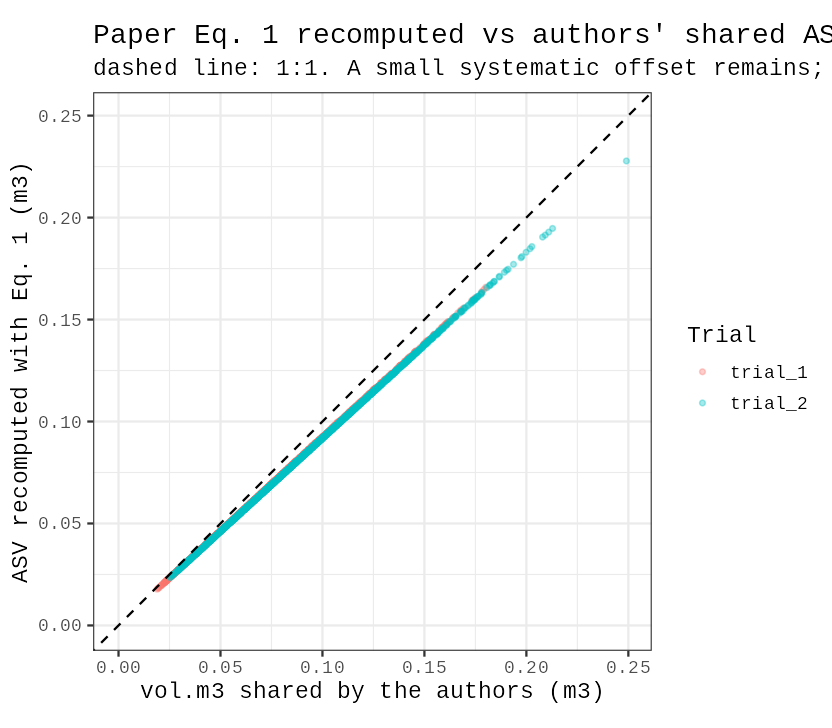

In [ ]:
import subprocess, pathlib

eq1_r = r'''
# ASV recomputation with paper Eq. 1 and validation against the authors' vol.m3
suppressMessages({library(dplyr); library(ggplot2)})
dat <- readRDS('data/phenotypes_anonymised.rds')
d <- dat %>% filter(!is.na(.data[['dbh.m']]), !is.na(.data[['zmax.m']]), !is.na(.data[['vol.m3']]))
# Eq. 1 (Kimberley & Beets 2007): ASV (m3) from DBH (cm) and zmax (m)
d$asv_eq1 <- 7.854e-5 * d[['zmax.m']] * (d[['dbh.m']] * 100)^2 *
             (0.304 + 0.860 * (d[['zmax.m']] - 1.4)^(-0.972))
r <- cor(d$asv_eq1, d[['vol.m3']])
ratio <- d$asv_eq1 / d[['vol.m3']]
cat('n =', nrow(d), 'trees with dbh.m, zmax.m and vol.m3\n')
cat(sprintf('Pearson r (Eq.1 ASV vs vol.m3) = %.6f\n', r))
cat(sprintf('ratio asv/vol.m3: median %.4f  sd %.4f  q05 %.4f  q95 %.4f\n',
            median(ratio), sd(ratio), quantile(ratio, .05), quantile(ratio, .95)))
write.csv(data.frame(n = nrow(d), pearson_r = r, ratio_median = median(ratio),
                     ratio_sd = sd(ratio)),
          'out/asv_eq1_validation.csv', row.names = FALSE)
p <- ggplot(d, aes(x = .data[['vol.m3']], y = asv_eq1, colour = trial)) +
  geom_point(alpha = 0.35, size = 1.1) +
  geom_abline(slope = 1, intercept = 0, linetype = 'dashed') +
  coord_fixed(xlim = c(0, max(d[['vol.m3']])), ylim = c(0, max(d[['vol.m3']]))) +
  labs(title = "Paper Eq. 1 recomputed vs authors' shared ASV (vol.m3)",
       subtitle = 'dashed line: 1:1. A small systematic offset remains; see notebook text.',
       x = 'vol.m3 shared by the authors (m3)', y = 'ASV recomputed with Eq. 1 (m3)',
       colour = 'Trial') +
  theme_bw(13)
ggsave('out/asv_eq1_vs_volm3.png', p, width = 6.4, height = 5.6, dpi = 130)
cat('saved out/asv_eq1_vs_volm3.png\n')
'''
pathlib.Path('script_b_eq1.R').write_text(eq1_r)
r = subprocess.run(['Rscript', 'script_b_eq1.R'], capture_output=True, text=True, timeout=1200)
print(r.stdout)
if r.returncode:
    print(r.stderr[-2000:])
    raise RuntimeError(f'Eq.1 script failed (exit {r.returncode})')
from IPython.display import Image
Image(filename='out/asv_eq1_vs_volm3.png')

**Build the relationship matrices exactly as the authors do.** 🇯🇵 著者のスクリプトと同じ手順で関係行列を作成します。Steps: (1) the authors' pedigree-closure helper `ped.extract` (verbatim from `src/ped.extract.R`); (2) the authors' malformation filter on `trial_1`; (3) pedigree matrix A via `AGHmatrix::Amatrix(ploidy=2)`; (4) the authors' pre-computed genomic matrix G subset to the pedigree IDs; (5) `ASRgenomics::G.inverse`, then `ASRgenomics::H.inverse(A, Ginv, lambda=0.5)` — the blended H⁻¹ of the paper (§2.4). The dense inverse form is used because sommer consumes a full precision matrix (the authors passed the sparse triplet form to ASReml; the matrix is mathematically the same).

In [ ]:
import subprocess, pathlib

fit_r = r'''
# Single-site ssGBLUP for trial_1 / zmax.m
# Matrix construction follows the authors' model_ssGBLUP_singlesite.R (commit ec9ed8f)
suppressMessages({library(dplyr)})
dat <- readRDS('data/phenotypes_anonymised.rds')
ped <- readRDS('data/pedigree_anonymised.rds')
G <- readRDS('data/Gmatrix_anonymised.rds')

# Author's pedigree-closure helper: src/ped.extract.R (verbatim logic)
ped.extract <- function(x, reference) {
  rpbc.ped <- reference; i <- 0; ped.length <- c(0); keep_going <- TRUE
  while (keep_going) {
    i <- i + 1
    temp <- unique(c(rpbc.ped[which(rpbc.ped$Tree %in% x), 'Tree'],
                     rpbc.ped[which(rpbc.ped$Tree %in% x), 'Mom'],
                     rpbc.ped[which(rpbc.ped$Tree %in% x), 'Dad']))
    ped.length[i] <- length(temp); x <- temp
    if (i > 1 && ped.length[i] == ped.length[i-1]) keep_going <- FALSE
  }
  list(pedigree = rpbc.ped[which(rpbc.ped$Tree %in% temp), ], ped_depth = i)
}

# Author's malformation filter (model_ssGBLUP_singlesite.R, trial_1, zmax.m)
t1 <- dat %>% filter(trial == 'trial_1') %>%
  filter(!grepl('ML|DL|FK|BW|BL|BT|DF|LL|LR|TO', tree_form_code)) %>%
  mutate(across(c(grid_id, GenotypeName), droplevels))
t1$GenotypeName2 <- t1$GenotypeName  # separate column for the ide() term
cat('trial_1 filtered rows:', nrow(t1), ' genotypes:', nlevels(t1$GenotypeName), '\n')

pedx <- ped.extract(x = t1[['GenotypeName']], reference = ped)[[1]] %>%
  mutate(across(everything(), as.factor))
cat('pedigree subset incl. ancestors:', nrow(pedx), '\n')

# A, G, H exactly as in the authors' script
Ax <- AGHmatrix::Amatrix(data = pedx, ploidy = 2, dominance = FALSE)
Gx <- G[which(rownames(G) %in% pedx$Tree), which(colnames(G) %in% pedx$Tree)]
Gx_inv <- ASRgenomics::G.inverse(G = Gx, sparseform = FALSE)$Ginv
Hx <- ASRgenomics::H.inverse(A = Ax, G = Gx_inv, lambda = 0.5, sparseform = FALSE)
Hmat <- as.matrix(Hx)
attr(Hmat, 'inverse') <- TRUE
cat('A:', nrow(Ax), 'x', ncol(Ax), ' Gx:', nrow(Gx), 'x', ncol(Gx),
    ' Hinv:', nrow(Hmat), 'x', ncol(Hmat), '\n')

# REML with sommer (open source) instead of commercial ASReml-R [ADAPTATION]
suppressMessages(library(sommer))
m <- mmes(fixed = zmax.m ~ 1,
          random = ~ vsm(ism(grid_id)) +
                     vsm(ism(GenotypeName), Gu = Hmat) +
                     vsm(ism(GenotypeName2)),
          data = as.data.frame(t1))

cp <- covparams_mmes_se(m)
print(as.data.frame(cp[, c('term', 'parameter', 'estimate', 'StdError')]))
vc <- attr(cp, 'vcov')

i_non <- grep('GenotypeName2', cp$term)
i_add <- setdiff(grep('GenotypeName', cp$term), i_non)
i_res <- grep('units', cp$term)
stopifnot(length(i_add) == 1, length(i_non) == 1, length(i_res) == 1)
Va <- cp$estimate[i_add]; Vi <- cp$estimate[i_non]; Ve <- cp$estimate[i_res]
tot <- Va + Vi + Ve
h2 <- Va / tot
grad <- c((Vi + Ve) / tot^2, -Va / tot^2, -Va / tot^2)  # dh2/d(Va,Vi,Ve)
C <- vc[c(i_add, i_non, i_res), c(i_add, i_non, i_res)]
h2se <- sqrt(as.numeric(t(grad) %*% C %*% grad))
cat(sprintf('\nVa(additive) = %.4f   V_nonadd(ide) = %.4f   V_resid = %.4f\n', Va, Vi, Ve))
cat(sprintf('narrow-sense h2 (zmax.m, trial_1) = %.3f  (delta-method SE %.3f)\n', h2, h2se))

# Published reference: per-site zmax h2 values, paper Table 4 (VOR)
zmax_sites <- c(0.41, 0.31, 0.47, 0.32, 0.50, 0.42, 0.33, 0.32, 0.40, 0.32, 0.23)
cat(sprintf('published per-site zmax h2 (Table 4): min %.2f max %.2f mean %.2f\n',
            min(zmax_sites), max(zmax_sites), mean(zmax_sites)))

res <- data.frame(
  component = c('grid_id (block)', 'additive (H, ssGBLUP)', 'non-additive (ide)', 'residual'),
  variance = c(cp$estimate[1], Va, Vi, Ve),
  std_error = c(cp$StdError[1], cp$StdError[i_add], cp$StdError[i_non], cp$StdError[i_res]),
  trait = 'zmax.m', trial = 'trial_1')
out <- rbind(res, data.frame(component = 'narrow-sense h2 (delta-method SE)',
                             variance = h2, std_error = h2se,
                             trait = 'zmax.m', trial = 'trial_1'))
write.csv(out, 'out/ssgblup_trial1_zmax_results.csv', row.names = FALSE)

suppressMessages(library(ggplot2))
site_df <- data.frame(h2 = zmax_sites)
p <- ggplot() +
  geom_point(data = site_df, aes(x = 'published sites\n(paper Table 4)', y = h2),
             alpha = 0.6, size = 2) +
  geom_pointrange(data = data.frame(x = 'this notebook\n(trial_1, sommer)', h2 = h2, se = h2se),
                  aes(x = x, y = h2, ymin = h2 - se, ymax = h2 + se), colour = 'red') +
  ylim(0, 0.6) +
  labs(title = 'Narrow-sense h2 of zmax: single-site ssGBLUP (H, blending 0.5)',
       subtitle = paste('red: this notebook (sommer REML); black: published per-site values;',
                        'site mapping of anonymised trials is unknown'),
       x = NULL, y = 'narrow-sense heritability') +
  theme_bw(13)
ggsave('out/h2_vs_published.png', p, width = 7, height = 5, dpi = 130)
cat('saved out/ssgblup_trial1_zmax_results.csv and out/h2_vs_published.png\n')
'''
pathlib.Path('script_c_ssblup.R').write_text(fit_r)
r = subprocess.run(['Rscript', 'script_c_ssblup.R'], capture_output=True, text=True, timeout=2400)
print(r.stdout)
if r.returncode:
    print(r.stderr[-3000:])
    raise RuntimeError(f'ssGBLUP script failed (exit {r.returncode})')
print('--- saved outputs ---')
for f in sorted(pathlib.Path('out').glob('*')):
    print(f, f.stat().st_size, 'bytes')

trial_1 filtered rows: 1382  genotypes: 1269 
pedigree subset incl. ancestors: 1680 
Verifying conflicting data...
Organizing data...
Your data was chronologically organized with success.
Processing large pedigree data. It may take a couple of minutes...
Constructing matrix A using ploidy = 2
Completed! Time = 0 minutes
A: 1680 x 1680  Gx: 1434 x 1434  Hinv: 1680 x 1680 
BLAS backend: /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3.
BLAS threads configured: unknown (unavailable); allocation-aware CPUs: unknown.
Adding 411 additional Gu levels to the main-effect model matrix: 2463, 2511, 2227, 526, 4291, 2986, 1842, 1142, 3371, 5134 ... 
MME path: AI-first with on-demand EM/PX-GEM recovery [solver=cholmod; latent RR=inactive; Schur=inactive (auto: not selected); chain=inactive; banded=inactive; factor-Schur=inactive; residual=diagonal; grid=inactive; repeated-Kronecker=inactive]
 iter         LogLik    deltaLL       update          policy  trust   line   notPD  time(s)
    1    

**Display the heritability result against the published reference values.** 🇯🇵 推定された遺伝率（赤、信頼区間付き）を、論文Table 4のサイト別zmax遺伝率（黒）と並べて表示します。The anonymised trials cannot be mapped to named sites, so this is a plausibility comparison with the published range, not a one-to-one check. The CSV is saved under `out/` and can be downloaded from the Colab file browser.

,component,variance,std_error,trait,trial
0,grid_id (block),0.172588,0.038313,zmax.m,trial_1
1,"additive (H, ssGBLUP)",0.281309,0.064833,zmax.m,trial_1
2,non-additive (ide),0.176731,0.066223,zmax.m,trial_1
3,residual,0.431629,0.056090,zmax.m,trial_1
4,narrow-sense h2 (delta-method SE),0.316196,0.061438,zmax.m,trial_1


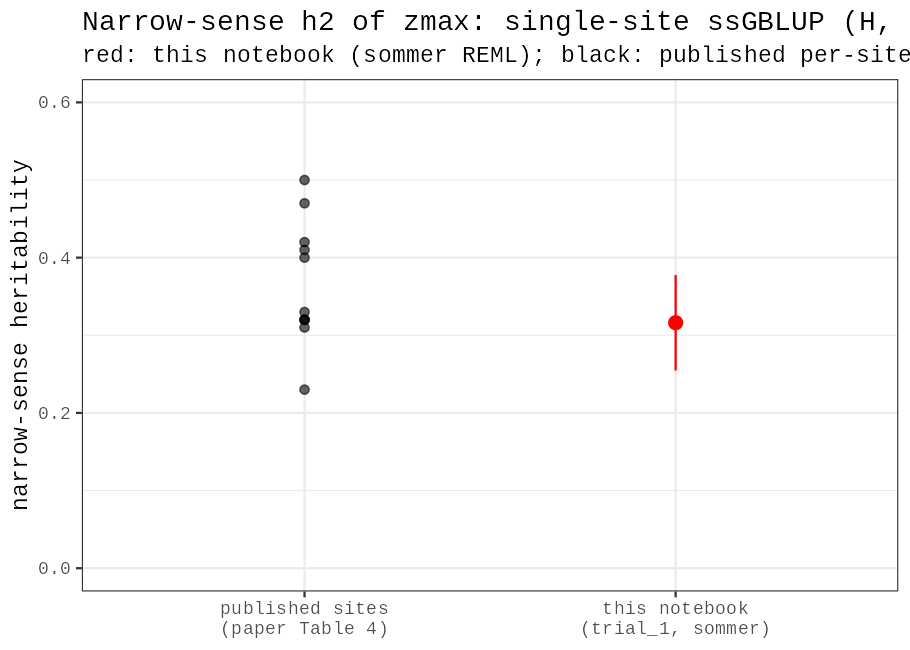

In [ ]:
from IPython.display import Image
import pandas as pd

display(pd.read_csv('out/ssgblup_trial1_zmax_results.csv'))
Image(filename='out/h2_vs_published.png')

## Interpretation and validation record

🇯🇵 **結果の解釈** — このノートブックは、論文の単サイトssGBLUP解析パイプラインを1試験区×1形質（trial_1, zmax.m）で再現する**適応版デモ**です。

- **Matrix pipeline (faithful):** pedigree closure, `AGHmatrix::Amatrix`, the authors' shared G matrix, `ASRgenomics::G.inverse` / `H.inverse(λ=0.5)` follow the authors' `model_ssGBLUP_singlesite.R` (commit `ec9ed8f`) and the paper §2.4 formulas.
- **REML engine (adapted):** sommer replaces the commercial ASReml-R. Variance components, the h² formula V_A/(V_A+V_non-add+V_res) and delta-method standard errors follow the authors' `vpredict` usage and paper §2.5. sommer and ASReml use the same REML objective, but optimiser details can differ slightly.
- **ASV Eq. 1 check:** the recomputed ASV correlates ≈1 with the authors' `vol.m3`, with a small systematic offset (the printed constants are rounded); exact statistics are in the outputs above.
- **Heritability plausibility:** the estimated h² for `zmax.m` in trial_1 is compared with the published per-site values (paper Table 4, zmax h² 0.23–0.50 across 11 sites); the trial identity of `trial_1` is anonymised, so only range-level agreement can be judged.
- **Not verified here:** site-level EBVs, selection-utility results, multi-site models, genetic correlations, and the paper's dataset-level conclusions.

**References:** paper DOI 10.1186/s13595-026-01379-x · author code commit `ec9ed8f5055abf9f2aecda4fad18781df7a24469` · Kimberley & Beets (2007) allometric equation · AGHmatrix (Amadeu et al. 2016) · ASRgenomics (Gezan et al., CRAN, MIT) · sommer (Covarrubias-Pazaran, GPL-3). Data files © the authors, shared via the author repository; no licence file — reuse beyond this demonstration requires author permission.